# Predicting p_success_g_challenge

We run the same steps as in p_challenge:
1. Data preprocessing
2. Measure baselines (dummy classfier + logistic regression)
3. Test more advanced models

In [236]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    log_loss,
    brier_score_loss,
    average_precision_score,
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import RandomOverSampler, SMOTE
from xgboost import XGBClassifier

pd.set_option("display.max.columns", None)

In [237]:
data = pd.read_excel("../data-train.xlsx")
print(len(data))

309063


In [238]:
metadata = ["play_id", "venue_id", "pitcher_id", "batter_id", "catcher_id", "umpire_id", "game_id"]
non_target_features = ["challenge_source", "is_success"]
given_challenge = data[data["is_challenge"]==1]
# drops rows where columns not in non_target_features contain NaN
ignore = given_challenge.columns.difference(non_target_features)
given_challenge = given_challenge.dropna(subset=ignore)
groups = given_challenge.loc[given_challenge.index, "game_id"]  # not a feature, only used to split by game
given_challenge = given_challenge.drop(metadata, axis=1)
print(len(given_challenge))
print(given_challenge["challenge_source"].value_counts())
given_challenge.head()


8315
challenge_source
pitching_team    4285
hitting_team     4030
Name: count, dtype: int64


,balls,strikes,outs,inning,is_top_inning,pitcher_hand,batter_hand,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,challenge_source,is_success
21,2,2,2,9,True,Right,Right,called_strike,6,3,87.752120,3.628345,12.680988,1.538168,4.893047,-1.529497,-0.729674,5.446059,0.440179,2.155370,3.344,1.688,74,5,1,hitting_team,0.0
68,1,1,0,9,True,Right,Right,called_strike,8,4,89.562322,16.488701,9.079635,1.475463,5.076874,-3.185333,-1.475181,5.690820,-0.105933,1.438055,3.214,1.622,72,3,1,hitting_team,1.0
69,0,0,0,9,True,Right,Right,called_strike,8,4,89.982638,18.567762,5.507758,1.617036,5.033417,-3.060257,0.915572,5.631256,0.315047,3.333370,3.214,1.622,72,1,1,hitting_team,1.0
88,1,2,1,8,False,Right,Left,called_strike,3,3,90.394122,17.373805,9.024242,1.509568,5.071255,-3.840544,-0.912275,5.527856,-0.676132,2.136581,3.479,1.756,61,5,1,hitting_team,0.0
94,1,1,2,8,False,Right,Right,called_strike,4,6,89.433332,3.361946,13.175525,1.464954,4.959741,-2.715712,-1.152274,5.541360,-0.755602,2.133051,3.181,1.605,70,3,1,hitting_team,0.0


In [239]:
# relabel binary features
# if challenge_source is pitching_team, we label is 1. this choice is arbitrary
positive_values = {
    "is_top_inning": True,
    "pitcher_hand": "Right",
    "batter_hand": "Right",
    "pitch_result": "called_strike",
    "challenge_source": "hitting_team",
    "is_success": True
}

for f, positive in positive_values.items():
    given_challenge[f] = (given_challenge[f] == positive).astype("int64")

given_challenge.head()

,balls,strikes,outs,inning,is_top_inning,pitcher_hand,batter_hand,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,challenge_source,is_success
21,2,2,2,9,1,1,1,1,6,3,87.752120,3.628345,12.680988,1.538168,4.893047,-1.529497,-0.729674,5.446059,0.440179,2.155370,3.344,1.688,74,5,1,1,0
68,1,1,0,9,1,1,1,1,8,4,89.562322,16.488701,9.079635,1.475463,5.076874,-3.185333,-1.475181,5.690820,-0.105933,1.438055,3.214,1.622,72,3,1,1,1
69,0,0,0,9,1,1,1,1,8,4,89.982638,18.567762,5.507758,1.617036,5.033417,-3.060257,0.915572,5.631256,0.315047,3.333370,3.214,1.622,72,1,1,1,1
88,1,2,1,8,0,1,0,1,3,3,90.394122,17.373805,9.024242,1.509568,5.071255,-3.840544,-0.912275,5.527856,-0.676132,2.136581,3.479,1.756,61,5,1,1,0
94,1,1,2,8,0,1,1,1,4,6,89.433332,3.361946,13.175525,1.464954,4.959741,-2.715712,-1.152274,5.541360,-0.755602,2.133051,3.181,1.605,70,3,1,1,0


In [240]:
given_challenge.describe()

,balls,strikes,outs,inning,is_top_inning,pitcher_hand,batter_hand,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,challenge_source,is_success
count,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.00000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.000000,8315.0,8315.000000,8315.000000
mean,1.132171,0.949369,1.006013,5.189657,0.510643,0.781239,0.548767,0.48623,2.685869,2.962838,89.085184,2.242083,7.627627,0.996817,5.715196,-1.312410,-1.181140,5.821324,-0.043837,2.260031,3.205516,1.617758,42.287793,3.228262,1.0,0.484666,0.491882
std,1.080573,0.834925,0.822005,2.544431,0.499917,0.413431,0.497646,0.49984,2.893497,3.074402,5.837072,10.337576,8.269983,1.838906,0.496596,2.532402,1.488376,0.418073,0.649793,0.691611,0.109727,0.055408,23.061022,1.881911,0.0,0.499795,0.499964
min,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,57.175216,-23.491412,-20.722791,-4.420640,2.901168,-7.409677,-5.048401,3.755460,-1.362921,1.056359,2.898000,1.463000,1.000000,1.000000,1.0,0.000000,0.000000
25%,0.000000,0.000000,0.000000,3.000000,0.000000,1.000000,0.000000,0.00000,0.000000,0.000000,84.631213,-5.637932,2.424785,0.577469,5.450476,-3.133279,-2.290502,5.553280,-0.681939,1.628305,3.128000,1.579000,23.000000,2.000000,1.0,0.000000,0.000000
50%,1.000000,1.000000,1.000000,5.000000,1.000000,1.000000,1.000000,0.00000,2.000000,2.000000,90.331925,3.338719,8.315274,1.599260,5.766616,-1.878087,-1.244525,5.822698,-0.072472,2.101053,3.202000,1.616000,43.000000,3.000000,1.0,0.000000,0.000000
75%,2.000000,2.000000,2.000000,7.000000,1.000000,1.000000,1.000000,1.00000,4.000000,5.000000,93.713178,11.135653,14.536719,2.217486,6.047079,-0.067032,-0.191017,6.089245,0.611365,2.906542,3.274000,1.652000,61.000000,5.000000,1.0,1.000000,1.000000
max,3.000000,2.000000,2.000000,13.000000,1.000000,1.000000,1.000000,1.00000,20.000000,23.000000,101.763114,24.588368,25.811258,4.917727,7.417921,6.422422,3.895461,7.704930,1.772274,3.861387,3.572000,1.803000,111.000000,13.000000,1.0,1.000000,1.000000


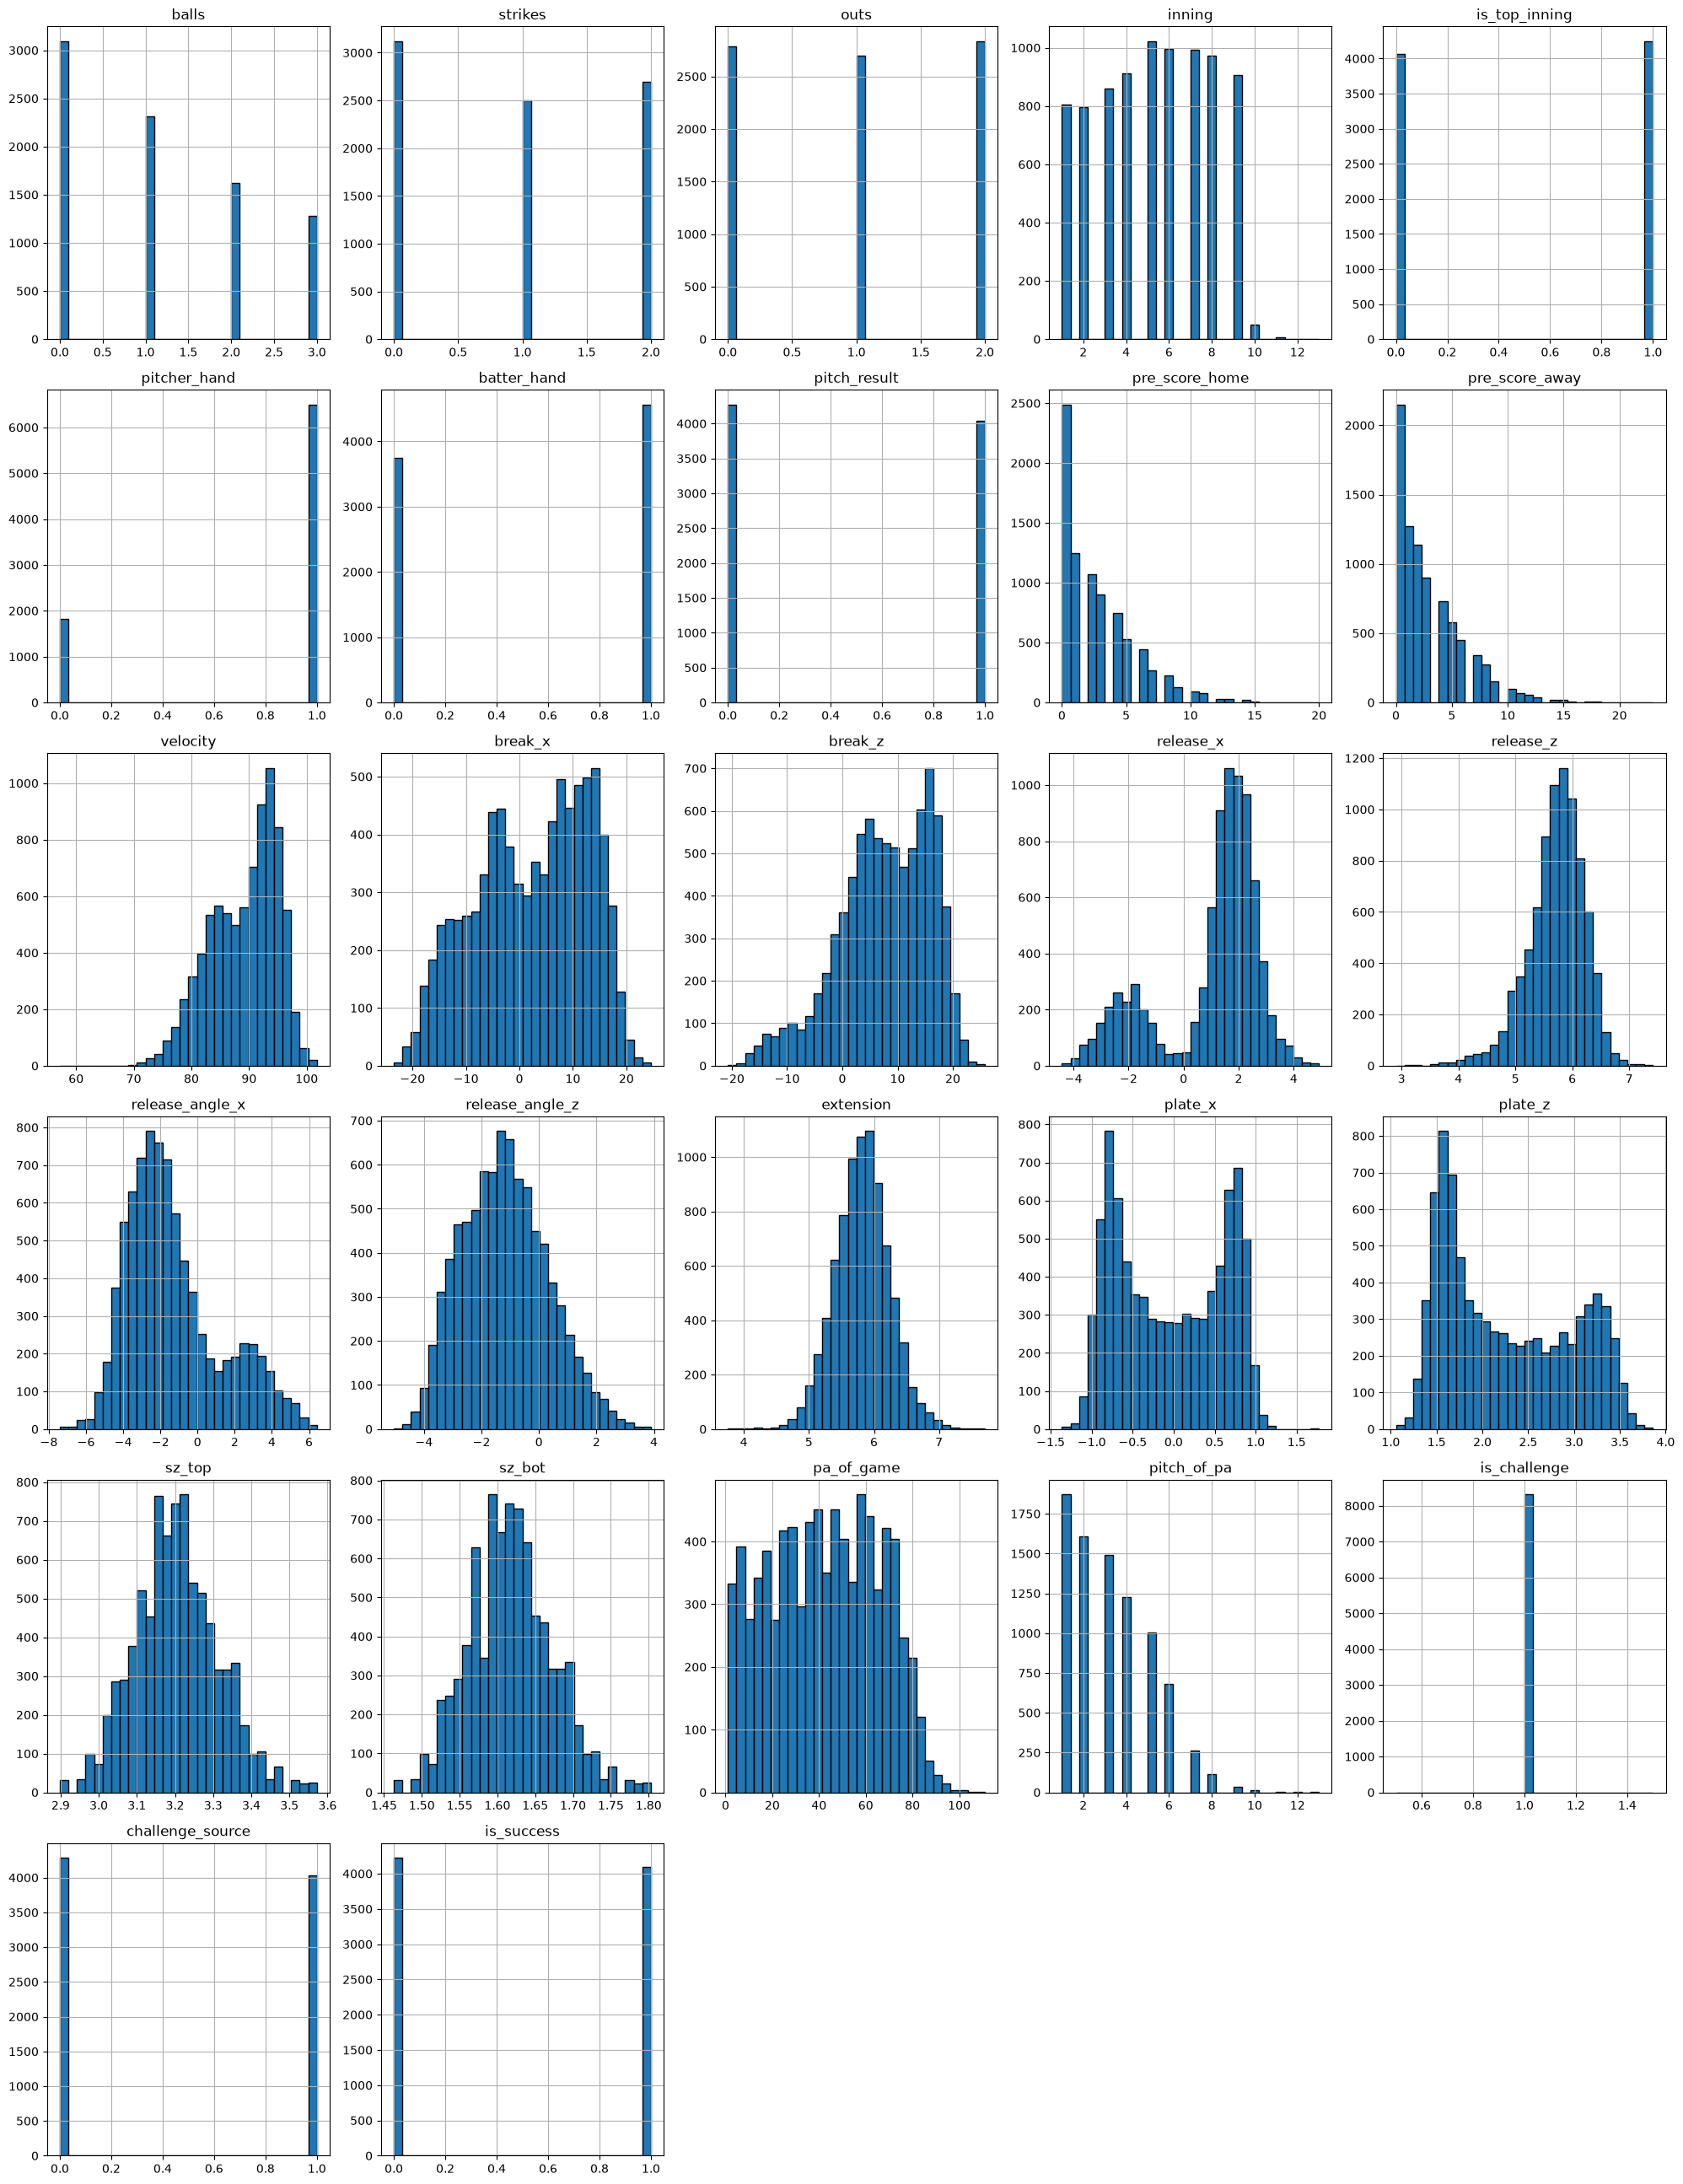

In [241]:
given_challenge.hist(figsize=(20, 26), bins=30, layout=(-1, 5), edgecolor="black")
plt.tight_layout()
plt.show()

In [242]:
X = given_challenge.drop(["is_success", "is_challenge"], axis=1)
y = given_challenge.pop("is_success")
# input features
X.head()

,balls,strikes,outs,inning,is_top_inning,pitcher_hand,batter_hand,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,challenge_source
21,2,2,2,9,1,1,1,1,6,3,87.752120,3.628345,12.680988,1.538168,4.893047,-1.529497,-0.729674,5.446059,0.440179,2.155370,3.344,1.688,74,5,1
68,1,1,0,9,1,1,1,1,8,4,89.562322,16.488701,9.079635,1.475463,5.076874,-3.185333,-1.475181,5.690820,-0.105933,1.438055,3.214,1.622,72,3,1
69,0,0,0,9,1,1,1,1,8,4,89.982638,18.567762,5.507758,1.617036,5.033417,-3.060257,0.915572,5.631256,0.315047,3.333370,3.214,1.622,72,1,1
88,1,2,1,8,0,1,0,1,3,3,90.394122,17.373805,9.024242,1.509568,5.071255,-3.840544,-0.912275,5.527856,-0.676132,2.136581,3.479,1.756,61,5,1
94,1,1,2,8,0,1,1,1,4,6,89.433332,3.361946,13.175525,1.464954,4.959741,-2.715712,-1.152274,5.541360,-0.755602,2.133051,3.181,1.605,70,3,1


In [243]:
#labels
y.head()

21    0
68    1
69    1
88    0
94    0
Name: is_success, dtype: int64

In [244]:
# we randomly split by games
test_games = pd.read_excel("../data-test.xlsx", usecols=["game_id"])["game_id"]
print("games shared by data-train.xlsx and data-test.xlsx:", len(set(data["game_id"]) & set(test_games)))

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=67)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"train: {len(X_train)} pitches, {groups_train.nunique()} games, challenge success rate {y_train.mean():.4f}")
print(f"test:  {len(X_test)} pitches, {groups.iloc[test_idx].nunique()} games, challenge success rate {y_test.mean():.4f}")

games shared by data-train.xlsx and data-test.xlsx: 0
train: 6674 pitches, 1576 games, challenge success rate 0.4912
test:  1641 pitches, 394 games, challenge success rate 0.4948


# Model Evaluation Metrics

We use the same metrics as in p_challenge.ipynb.

In [245]:
results = {}
probas = {}

def evaluate(name, model):
    p = model.predict_proba(X_test)[:, 1]
    # y_pred = model.predict(X_test)
    # print(classification_report(y_test, y_pred, target_names=["upheld", "overturned"], zero_division=0))
    results[name] = {
        "log_loss": log_loss(y_test, p),
        "auroc": roc_auc_score(y_test, p),
        "avg_precision": average_precision_score(y_test, p),
        "mean_p": p.mean(),
        "max_p": p.max(),
    }
    probas[name] = p
    print(pd.Series(results[name]).round(4).to_string())
    # ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["upheld", "overturned"], cmap="Blues")
    # plt.title(f"{name} Confusion Matrix")
    # plt.show()

## Baselines

In [246]:
# always predicts the training success rate of around 49%
prior = DummyClassifier(strategy="prior").fit(X_train, y_train)
evaluate("Base rate", prior)

log_loss         0.6931
auroc            0.5000
avg_precision    0.4948
mean_p           0.4912
max_p            0.4912


In [247]:
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    clf = LogisticRegression(max_iter=1000, random_state=67).fit(X_train, y_train)
    evaluate("Logistic Regression", clf)

log_loss         0.6822
auroc            0.5898
avg_precision    0.5432
mean_p           0.4869
max_p            0.7004


/opt/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Observations
- As expected, baseline models have extremely low AUROC scores.

## Decision Trees

In [248]:
dt = DecisionTreeClassifier(random_state=67).fit(X_train, y_train)
print("depth:", dt.get_depth(), "leaves:", dt.get_n_leaves())
evaluate("Decision Tree (default)", dt)

# a fully grown tree has pure leaves, so its probabilities are almost all exactly 0 or 1
print("share of predictions that are exactly 0 or 1:", np.isin(probas["Decision Tree (default)"], [0, 1]).mean().round(3))

depth: 23 leaves: 704
log_loss         6.2599
auroc            0.8263
avg_precision    0.7663
mean_p           0.4966
max_p            1.0000
share of predictions that are exactly 0 or 1: 1.0


In [249]:
# tune tree size on log loss with 5-fold cross-validation over training games
# (smaller leaf sizes than p_challenge: there are ~6,700 training challenges, not ~250,000 pitches)
cv = GroupKFold(n_splits=5)
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=67),
    param_grid={
        "max_depth": [2, 3, 4, 6, 8, 10, None],
        "min_samples_leaf": [1, 10, 25, 50, 100, 200],
    },
    scoring="neg_log_loss",
    cv=cv,
    n_jobs=-1,
)
dt_grid.fit(X_train, y_train, groups=groups_train)
print("best params:", dt_grid.best_params_, " CV log loss:", round(-dt_grid.best_score_, 4))

best params: {'max_depth': 10, 'min_samples_leaf': 100}  CV log loss: 0.4774


base-rate CV log loss: 0.6932


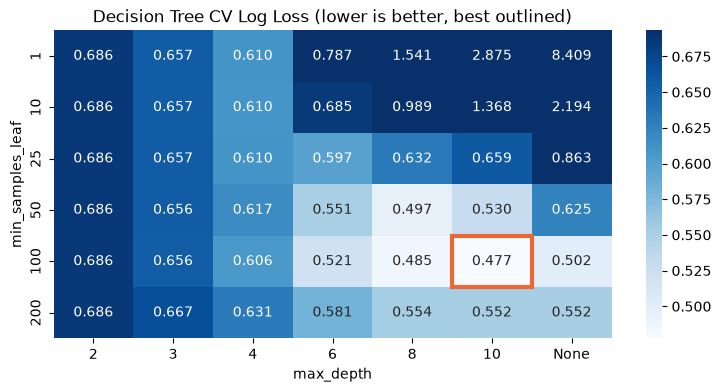

In [250]:
dt_cv = pd.DataFrame(dt_grid.cv_results_)
dt_cv["max_depth"] = dt_cv["param_max_depth"].fillna("None").astype(str)
dt_cv["log_loss"] = -dt_cv["mean_test_score"]
heat = dt_cv.pivot(index="param_min_samples_leaf", columns="max_depth", values="log_loss")
heat = heat[[str(d) for d in dt_grid.param_grid["max_depth"]]]

# base-rate log loss on the same folds; the colour scale tops out there,
# so the darkest cells do no better than always predicting the base rate
base_cv = -cross_val_score(
    DummyClassifier(strategy="prior"), X_train, y_train, groups=groups_train, cv=cv, scoring="neg_log_loss"
).mean()
print("base-rate CV log loss:", round(base_cv, 4))

plt.figure(figsize=(9, 4))
ax = sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues", vmax=base_cv)
best_cell = (
    heat.columns.get_loc(str(dt_grid.best_params_["max_depth"])),
    heat.index.get_loc(dt_grid.best_params_["min_samples_leaf"]),
)
ax.add_patch(plt.Rectangle(best_cell, 1, 1, fill=False, edgecolor="#eb6834", lw=3))
plt.title("Decision Tree CV Log Loss (lower is better, best outlined)")
plt.xlabel("max_depth")
plt.ylabel("min_samples_leaf")
plt.show()

In [251]:
best_dt = dt_grid.best_estimator_  # refit on all training games with the best params
print("depth:", best_dt.get_depth(), "leaves:", best_dt.get_n_leaves())
evaluate("Decision Tree (tuned)", best_dt)

depth: 10 leaves: 45
log_loss         0.4553
auroc            0.8658
avg_precision    0.8448
mean_p           0.4849
max_p            0.9625


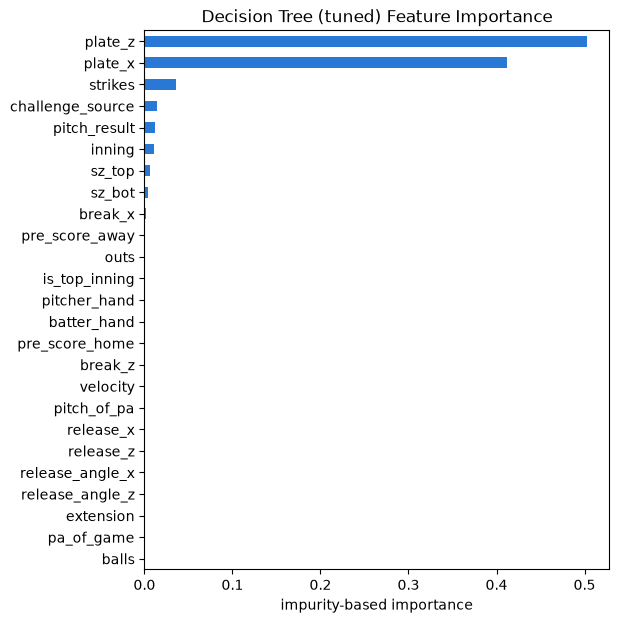

In [252]:
pd.Series(best_dt.feature_importances_, index=X.columns).sort_values().plot.barh(figsize=(6, 7), color="#2a78d6")
plt.title("Decision Tree (tuned) Feature Importance")
plt.xlabel("impurity-based importance")
plt.show()

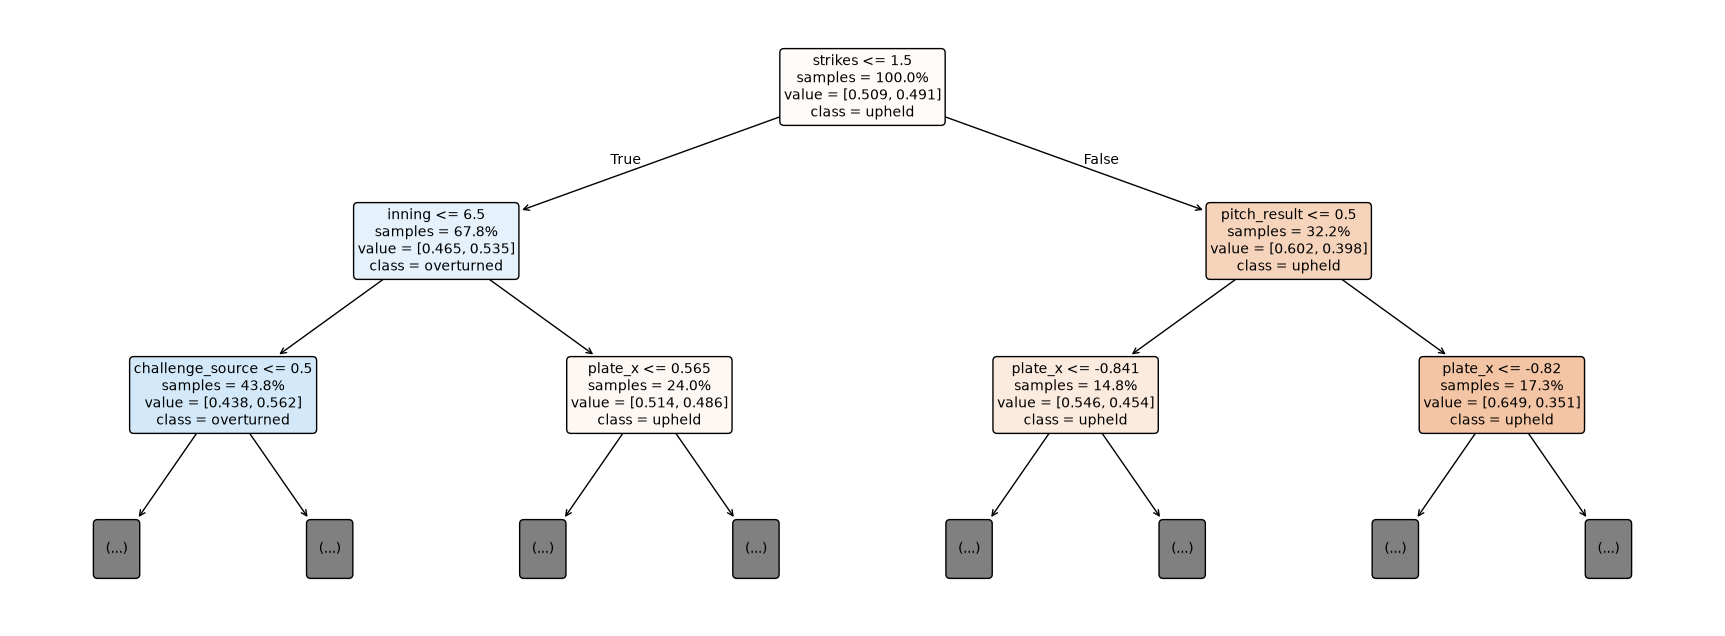

In [253]:
# first three levels of the tuned tree (value = share of [upheld, overturned] in the node)
plt.figure(figsize=(22, 8))
plot_tree(
    best_dt,
    max_depth=2,
    feature_names=X.columns.tolist(),
    class_names=["upheld", "overturned"],
    filled=True,
    impurity=False,
    proportion=True,
    rounded=True,
    fontsize=10,
)
plt.show()

## Random forest

In [254]:
rf = RandomForestClassifier(n_jobs=-1, random_state=67).fit(X_train, y_train)
evaluate("Random Forest (default)", rf)

log_loss         0.4209
auroc            0.9278
avg_precision    0.9244
mean_p           0.4929
max_p            0.9700


In [255]:
# tune leaf size and features per split on log loss over training games
# (small dataset, so the same 5 folds as the tree and full-size bootstrap samples are quick)
rf_grid = GridSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=67),
    param_grid={
        "min_samples_leaf": [1, 5, 20, 50],
        "max_features": ["sqrt", 0.5],
    },
    scoring="neg_log_loss",
    cv=cv,
)
rf_grid.fit(X_train, y_train, groups=groups_train)
print("best params:", rf_grid.best_params_, " CV log loss:", round(-rf_grid.best_score_, 4))

rf_cv = pd.DataFrame(rf_grid.cv_results_)
rf_cv["cv_log_loss"] = -rf_cv["mean_test_score"]
rf_cv[["param_min_samples_leaf", "param_max_features", "cv_log_loss", "std_test_score", "mean_fit_time"]].sort_values("cv_log_loss").round(4)

best params: {'max_features': 0.5, 'min_samples_leaf': 1}  CV log loss: 0.3651


,param_min_samples_leaf,param_max_features,cv_log_loss,std_test_score,mean_fit_time
4,1,0.5,0.3651,0.0137,1.9403
5,5,0.5,0.3700,0.0132,1.6147
6,20,0.5,0.4070,0.0154,1.5330
0,1,sqrt,0.4510,0.0113,0.8148
7,50,0.5,0.4625,0.0157,1.8776
1,5,sqrt,0.4677,0.0063,0.6938
2,20,sqrt,0.5131,0.0073,0.5646
3,50,sqrt,0.5651,0.0062,0.5342


In [256]:
best_rf = rf_grid.best_estimator_
evaluate("Random Forest (tuned)", best_rf)

log_loss         0.3399
auroc            0.9426
avg_precision    0.9368
mean_p           0.4903
max_p            1.0000


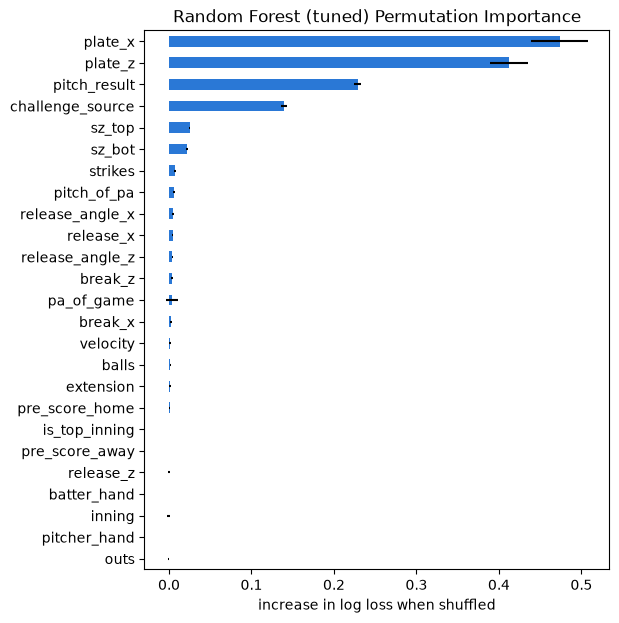

In [257]:
# permutation importance on the held-out games: how much worse log loss gets when a feature is shuffled
perm = permutation_importance(best_rf, X_test, y_test, scoring="neg_log_loss", n_repeats=5, random_state=67)
perm_importance = pd.DataFrame(
    {"mean": perm.importances_mean, "std": perm.importances_std}, index=X.columns
).sort_values("mean")

perm_importance["mean"].plot.barh(xerr=perm_importance["std"], figsize=(6, 7), color="#2a78d6")
plt.title("Random Forest (tuned) Permutation Importance")
plt.xlabel("increase in log loss when shuffled")
plt.show()

## XGBoost

In [258]:
xgb = XGBClassifier(random_state=67, n_jobs=-1).fit(X_train, y_train)
evaluate("XGBoost (default)", xgb)

log_loss         0.3269
auroc            0.9342
avg_precision    0.9301
mean_p           0.4989
max_p            0.9995


In [259]:
# boosted trees: tune tree depth, step size and number of trees on log loss,
# with the same 5-fold cross-validation over training games as the decision tree
xgb_grid = GridSearchCV(
    XGBClassifier(random_state=67, n_jobs=-1),
    param_grid={
        "max_depth": [3, 5, 7],
        "learning_rate": [0.05, 0.1],
        "n_estimators": [200, 500],
    },
    scoring="neg_log_loss",
    cv=cv,
)
xgb_grid.fit(X_train, y_train, groups=groups_train)
print("best params:", xgb_grid.best_params_, " CV log loss:", round(-xgb_grid.best_score_, 4))

xgb_cv = pd.DataFrame(xgb_grid.cv_results_)
xgb_cv["cv_log_loss"] = -xgb_cv["mean_test_score"]
xgb_cv[["param_max_depth", "param_learning_rate", "param_n_estimators", "cv_log_loss", "std_test_score", "mean_fit_time"]].sort_values("cv_log_loss").round(4)

best params: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}  CV log loss: 0.349


,param_max_depth,param_learning_rate,param_n_estimators,cv_log_loss,std_test_score,mean_fit_time
10,7,0.10,200,0.3490,0.0125,3.3049
5,7,0.05,500,0.3518,0.0122,6.9495
9,5,0.10,500,0.3525,0.0134,4.2029
11,7,0.10,500,0.3615,0.0193,5.3741
4,7,0.05,200,0.3735,0.0094,2.2017
8,5,0.10,200,0.3752,0.0090,3.2319
3,5,0.05,500,0.3796,0.0118,4.1573
7,3,0.10,500,0.4021,0.0151,2.1832
2,5,0.05,200,0.4234,0.0146,1.4985
1,3,0.05,500,0.4487,0.0165,2.3429


In [260]:
best_xgb = xgb_grid.best_estimator_
evaluate("XGBoost (tuned)", best_xgb)

log_loss         0.3237
auroc            0.9363
avg_precision    0.9328
mean_p           0.4943
max_p            0.9974


In [261]:
import json

# export the tuned XGBoost settings, so the model can be rebuilt later without rerunning the grid search:
#   XGBClassifier(**json.load(open("xgb_params_p_success.json"))).fit(X_train, y_train)
xgb_params = {k: v for k, v in best_xgb.get_params().items()
              if v is not None and not (isinstance(v, float) and np.isnan(v))}  # drop settings left at their defaults
with open("xgb_params_p_success.json", "w") as f:
    json.dump(xgb_params, f, indent=2)
xgb_params

{'objective': 'binary:logistic',
 'enable_categorical': True,
 'learning_rate': 0.1,
 'max_depth': 7,
 'n_estimators': 200,
 'n_jobs': -1,
 'random_state': 67}

In [262]:
summary = pd.DataFrame(results).T.sort_values("log_loss")
print("actual success rate in held-out games:", round(y_test.mean(), 4))
summary.round(4)

actual success rate in held-out games: 0.4948


,log_loss,auroc,avg_precision,mean_p,max_p
XGBoost (tuned),0.3237,0.9363,0.9328,0.4943,0.9974
XGBoost (default),0.3269,0.9342,0.9301,0.4989,0.9995
Random Forest (tuned),0.3399,0.9426,0.9368,0.4903,1.0000
Random Forest (default),0.4209,0.9278,0.9244,0.4929,0.9700
Decision Tree (tuned),0.4553,0.8658,0.8448,0.4849,0.9625
Logistic Regression,0.6822,0.5898,0.5432,0.4869,0.7004
Base rate,0.6931,0.5000,0.4948,0.4912,0.4912
Decision Tree (default),6.2599,0.8263,0.7663,0.4966,1.0000


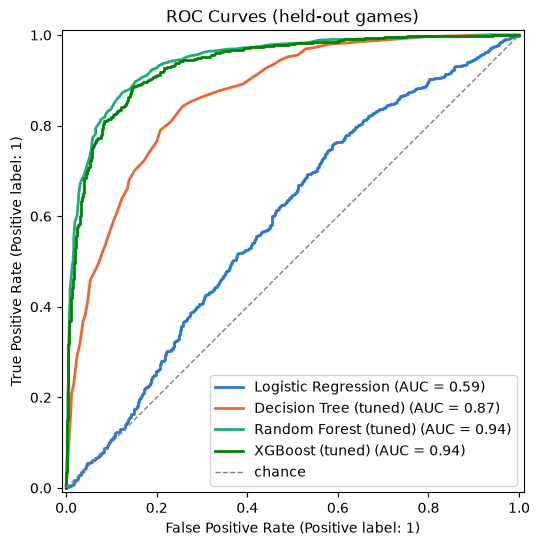

In [263]:
# one fixed colour per model across the plots below
colors = {
    "Logistic Regression": "#2a78d6",
    "Decision Tree (tuned)": "#eb6834",
    "Random Forest (tuned)": "#1baf7a",
    "XGBoost (tuned)": "#008300",
}

fig, ax = plt.subplots(figsize=(6, 6))
for name in colors.keys():
    RocCurveDisplay.from_predictions(y_test, probas[name], name=name, color=colors[name], lw=2, ax=ax)
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="gray", label="chance")
ax.legend(loc="lower right")
ax.set_title("ROC Curves (held-out games)")
plt.show()

### Observations
- Surprisingly, tuned RandomForest achieved a better AUROC curve than XGBoost, unlike the case for predicting p_challenge. However, looking at the calibration curve below shows XGBoost is better calibrated.

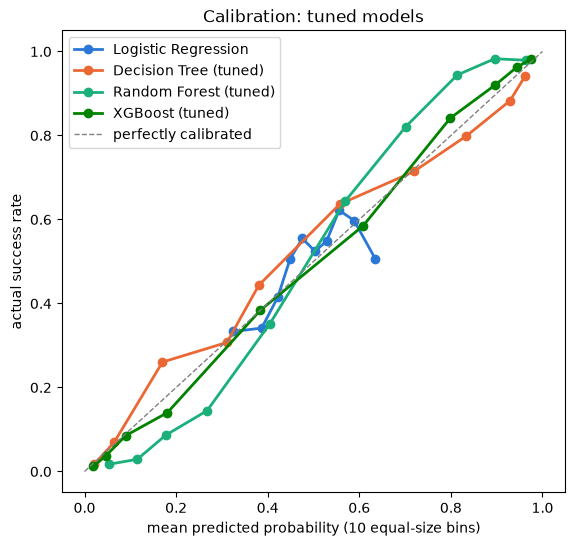

In [264]:
# calibration: within each bin of predicted probability, the share of challenges actually overturned.
# points on the dashed line mean the probabilities can be taken at face value
fig, ax = plt.subplots(figsize=(6.5, 6))
for name in colors.keys():
    prob_true, prob_pred = calibration_curve(y_test, probas[name], n_bins=10, strategy="quantile")
    ax.plot(prob_pred, prob_true, marker="o", lw=2, color=colors[name], label=name)
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="gray", label="perfectly calibrated")
ax.set_title("Calibration: tuned models")
ax.set_xlabel("mean predicted probability (10 equal-size bins)")
ax.set_ylabel("actual success rate")
ax.legend()
plt.show()

Again, since we are being graded on log loss, we will pick XGBoost as our best model.

# Strike zone: predicted success by challenge source

Let us assume hitters only challenge strike calls and the pitching team only ball calls. Then, we can visualize the predicted p_challenge_g_success as shown below:

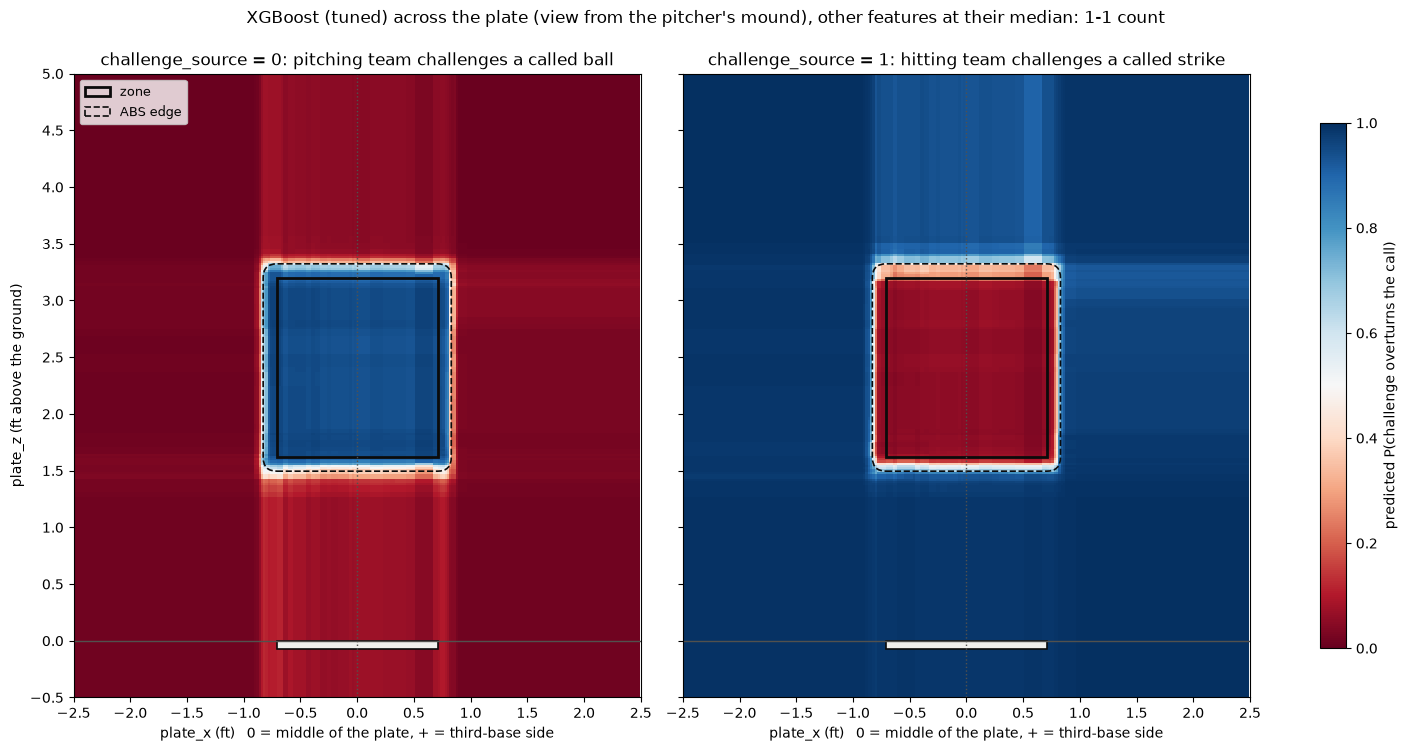

In [267]:
from matplotlib.patches import FancyBboxPatch, Rectangle

# the tuned model with the lowest held-out log loss (swap in any fitted model here)
tuned = {"Decision Tree (tuned)": best_dt, "Random Forest (tuned)": best_rf, "XGBoost (tuned)": best_xgb}
model_name = min(tuned, key=lambda n: results[n]["log_loss"])
model = tuned[model_name]

# only plate_x, plate_z and the challenge source (with its matching call) vary;
# every other feature is held at its median over the training challenges
fixed = X_train.median()
fixed["pitch_of_pa"] = fixed["balls"] + fixed["strikes"] + 1  # keep the pitch number consistent with the count

xs = np.arange(-2.5, 2.5, 0.02)
zs = np.arange(-0.5, 5.0, 0.02)
gx, gz = np.meshgrid(xs, zs)
grid = pd.DataFrame(np.tile(fixed.to_numpy(), (gx.size, 1)), columns=X.columns)
grid["plate_x"], grid["plate_z"] = gx.ravel(), gz.ravel()

panels = {
    "challenge_source = 0: pitching team challenges a called ball": (0, 0),
    "challenge_source = 1: hitting team challenges a called strike": (1, 1),
}
maps = {}
for title, (source, call) in panels.items():
    grid["challenge_source"], grid["pitch_result"] = source, call
    maps[title] = model.predict_proba(grid)[:, 1].reshape(gx.shape)

# strike zone from strike_zone.ipynb, using the same sz_top / sz_bot the model is given here
PLATE_HALF = 17 / 2 / 12  # home plate is 17 in wide
BALL_R = 1.45 / 12        # baseball radius (~1.45 in)
INK, INK2 = "#0b0b0b", "#52514e"

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True, layout="constrained")
for ax, (title, m) in zip(axes, maps.items()):
    # diverging scale centred on 0.5: blue = likely overturned, red = likely upheld
    mesh = ax.pcolormesh(xs, zs, m, cmap="RdBu", vmin=0, vmax=1, shading="auto")
    ax.add_patch(Rectangle((-PLATE_HALF, fixed["sz_bot"]), 2 * PLATE_HALF, fixed["sz_top"] - fixed["sz_bot"],
                           fill=False, ec=INK, lw=2, label="zone"))
    ax.add_patch(FancyBboxPatch((-PLATE_HALF, fixed["sz_bot"]), 2 * PLATE_HALF, fixed["sz_top"] - fixed["sz_bot"],
                                boxstyle=f"round,pad={BALL_R},rounding_size={BALL_R}",
                                fill=False, ec=INK, lw=1.2, ls="--", label="ABS edge"))
    ax.axhline(0, color=INK2, lw=1)
    ax.add_patch(Rectangle((-PLATE_HALF, -0.07), 2 * PLATE_HALF, 0.07, fc="#f0efec", ec=INK, lw=1.2))
    ax.axvline(0, color=INK2, ls=":", lw=1)
    ax.set(title=title, xlim=(-2.5, 2.5), ylim=(-0.5, 5.0), aspect="equal",
           xlabel="plate_x (ft)   0 = middle of the plate, + = third-base side")
    ax.set_xticks(np.arange(-2.5, 2.51, 0.5))
    ax.set_yticks(np.arange(-0.5, 5.01, 0.5))
axes[0].set_ylabel("plate_z (ft above the ground)")
axes[0].legend(loc="upper left", fontsize=9)
fig.colorbar(mesh, ax=axes, shrink=0.75, label="predicted P(challenge overturns the call)")
fig.suptitle(f"{model_name} across the plate (view from the pitcher's mound), "
             f"other features at their median: {fixed['balls']:.0f}-{fixed['strikes']:.0f} count")
plt.show()

### Observations
- We see that the zones where the model predicts a challenge to be successful for both hitters and the pitching team matches our expectation; called balls inside the zone gets overturned, while strikes outside the zone get overturned. This increases our confidence that the model actually learned the proper features.

In [266]:
import plotly.graph_objects as go
from IPython.display import HTML, display

# every challenge in the held-out games, at its real location, colored by the tuned XGBoost's predicted chance
# the call is overturned. filled = actually overturned, open = actually upheld.
# click a legend entry to show/hide it, double-click to show only that one; hover a pitch for details
held_out = data.loc[X_test.index].assign(
    p_overturned=best_xgb.predict_proba(X_test)[:, 1],
    outcome=np.where(y_test == 1, "overturned", "upheld"),
)

PLATE_HALF = 17 / 2 / 12  # home plate is 17 in wide
BALL_R = 1.45 / 12        # baseball radius (~1.45 in)
INK, INK2 = "#0b0b0b", "#52514e"
sz_top, sz_bot = X_train["sz_top"].median(), X_train["sz_bot"].median()

def abs_edge_text(df):
    # signed distance from each pitch's own ABS edge: its batter's sz_top / sz_bot and the plate, plus the ball's
    # radius, with rounded corners like the dashed outline (a ball exactly on the edge counts as inside)
    dx = df["plate_x"].abs() - PLATE_HALF
    dz = np.maximum(df["plate_z"] - df["sz_top"], df["sz_bot"] - df["plate_z"])
    inches = ((np.hypot(dx.clip(lower=0), dz.clip(lower=0)) + np.minimum(np.maximum(dx, dz), 0) - BALL_R) * 12).round(1)
    return inches.abs().map("{:.1f} in ".format) + np.where(inches > 0, "outside", "inside")

held_out["abs_edge"] = abs_edge_text(held_out)

fig = go.Figure()
for source, group in [("pitching_team", "Challenged by the pitching team"), ("hitting_team", "Challenged by the hitting team")]:
    for outcome, symbol in [("overturned", "circle"), ("upheld", "circle-open")]:
        pts = held_out[(held_out["challenge_source"] == source) & (held_out["outcome"] == outcome)]
        fig.add_trace(go.Scattergl(
            x=pts["plate_x"], y=pts["plate_z"], mode="markers",
            name=f"{outcome} ({len(pts)})", legendgroup=group, legendgrouptitle_text=group,
            marker=dict(color=pts["p_overturned"], coloraxis="coloraxis", symbol=symbol, size=8, line=dict(width=1.5)),
            customdata=np.stack([pts["play_id"], pts["pitch_result"], pts["balls"].astype(str) + "-" + pts["strikes"].astype(str),
                                 pts["inning"], pts["batter_hand"], pts["p_overturned"].map("{:.2f}".format), pts["abs_edge"],
                                 pts["sz_top"], pts["sz_bot"]], axis=1),
            hovertemplate=(f"<b>{group}: {outcome}</b><br>predicted P(overturned) %{{customdata[5]}}"
                           "<br>call: %{customdata[1]}, count %{customdata[2]}, inning %{customdata[3]}, %{customdata[4]}-handed batter"
                           "<br>ABS edge (this batter's zone): %{customdata[6]}"
                           "<br>plate_x %{x:.2f} ft, plate_z %{y:.2f} ft<br>play_id %{customdata[0]}<extra></extra>"),
        ))

# zone for the median batter, and the ABS edge one ball radius outside it (WebGL lines, drawn above the points)
fig.add_trace(go.Scattergl(
    x=[-PLATE_HALF, PLATE_HALF, PLATE_HALF, -PLATE_HALF, -PLATE_HALF], y=[sz_bot, sz_bot, sz_top, sz_top, sz_bot],
    mode="lines", line=dict(color=INK, width=2.5), name="zone (median batter)",
    legendgroup="Reference", legendgrouptitle_text="Reference", hoverinfo="skip",
))
arc = np.linspace(0, np.pi / 2, 12)
corners = [(PLATE_HALF, sz_top, 0), (-PLATE_HALF, sz_top, np.pi / 2), (-PLATE_HALF, sz_bot, np.pi), (PLATE_HALF, sz_bot, 1.5 * np.pi)]
edge_x = np.concatenate([cx + BALL_R * np.cos(start + arc) for cx, _, start in corners])
edge_z = np.concatenate([cz + BALL_R * np.sin(start + arc) for _, cz, start in corners])
fig.add_trace(go.Scattergl(
    x=np.append(edge_x, edge_x[0]), y=np.append(edge_z, edge_z[0]),
    mode="lines", line=dict(color=INK, width=1.5, dash="dash"), name="ABS edge",
    legendgroup="Reference", legendgrouptitle_text="Reference", hoverinfo="skip",
))
fig.add_vline(x=0, line=dict(color=INK2, width=1, dash="dot"))
fig.add_annotation(x=1.75, y=0.75, text="right-handed<br>batter's side →", showarrow=False, xanchor="right", font=dict(color=INK2))
fig.add_annotation(x=-1.75, y=0.75, text="← left-handed<br>batter's side", showarrow=False, xanchor="left", font=dict(color=INK2))

fig.update_layout(
    title=dict(text="Held-out challenges: predicted vs actual outcome (view from the pitcher's mound)",
               subtitle=dict(text="Color = tuned XGBoost's predicted chance the call is overturned; "
                                  "filled = actually overturned, open = actually upheld<br>"
                                  "Hover a pitch to see its batter's own zone (green)")),
    # diverging scale with a gray middle: red = likely upheld, blue = likely overturned
    coloraxis=dict(colorscale=[[0, "#b2182b"], [0.5, "#bdbdbd"], [1, "#2166ac"]], cmin=0, cmax=1,
                   colorbar=dict(title="predicted<br>P(overturned)")),
    width=950, height=920, plot_bgcolor="white", margin=dict(t=120),
    xaxis=dict(title="plate_x (ft)   0 = middle of the plate, + = third-base side",
               range=[-1.8, 1.8], dtick=0.25, gridcolor="#e1e0d9", zeroline=False),
    yaxis=dict(title="plate_z (ft above the ground)", range=[0.6, 4.2], dtick=0.25, gridcolor="#e1e0d9",
               zeroline=False, scaleanchor="x", scaleratio=1),
    legend=dict(groupclick="toggleitem", traceorder="grouped", orientation="h", y=-0.1),
)
# hovering a pitch draws its batter's own zone (solid) and ABS edge (dashed) in green; moving off removes them.
# a pitch's sz_top / sz_bot are the last two customdata entries
OWN_ZONE_ON_HOVER = """
const gd = document.getElementById('{plot_id}');
const base = (gd.layout.shapes || []).slice();
const PH = 17 / 24, R = 1.45 / 12, GREEN = '#008300';
function edgePath(top, bot) {
  const pts = [];
  for (const [cx, cz, a0] of [[PH, top, 0], [-PH, top, Math.PI / 2], [-PH, bot, Math.PI], [PH, bot, 1.5 * Math.PI]]) {
    for (let k = 0; k <= 8; k++) {
      const a = a0 + (Math.PI / 2) * k / 8;
      pts.push((cx + R * Math.cos(a)).toFixed(4) + ' ' + (cz + R * Math.sin(a)).toFixed(4));
    }
  }
  return 'M ' + pts.join(' L ') + ' Z';
}
gd.on('plotly_hover', ev => {
  const cd = ev.points[0].customdata;
  if (!cd) return;
  const top = parseFloat(cd[cd.length - 2]), bot = parseFloat(cd[cd.length - 1]);
  Plotly.relayout(gd, {shapes: base.concat([
    {type: 'rect', x0: -PH, x1: PH, y0: bot, y1: top, line: {color: GREEN, width: 2.5}, layer: 'above'},
    {type: 'path', path: edgePath(top, bot), line: {color: GREEN, width: 1.5, dash: 'dash'}, layer: 'above'},
  ])});
});
gd.on('plotly_unhover', () => Plotly.relayout(gd, {shapes: base}));
"""

display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False, post_script=OWN_ZONE_ON_HOVER)))

# Remarks:
- For overturned challenges, we expect p_success_g_challenge to be high (blue)
- For upheld challenges, we expect p_success_g_challenge to be low (red)

# Observations
- With the median batter's zone with the ABS zone, we can see that some challenged strikes that were overturned look almost look like they are clearly in the zone. However, hovering over them shows the adjusted strikezone (according to batter's height), revleading most of them were on the edges of the adjusted ABS strikezone.
- This does not explain however the horizontal variance in overturned strikes clearly inside the adjusted zone. We suspect this could either be due to faulty pitch coordinates or ABS not functioning reliably.

# Limitations/Places for imporovement

- As mentioned in p_challenge.ipynb, there were a number of anomalous calls where ABS seemed to be malfunctioning or the pitch coordinates might have been misread. I believe these calls contributed the model not being as confident in some areas of the zone, while not being confident enough in some areas of the zone.
